# Facial Expression Recognition: ResNet18 transfer learning

Eksperimen dua tahap di Google Colab GPU T4 untuk lima kelas: Angry, Fear, Happy,
Sad, dan Surprise. Gunakan **validation macro F1** untuk memilih checkpoint.
`RUN_FINAL_TEST` tetap `False` selama pengembangan. **Output yang masih terlihat
di bawah berasal dari run lama Stage 2 weight decay `1e-3` (best epoch 15,
validation macro F1 67,23%), bukan dari kode regularisasi yang baru.**
Jalankan ulang semua sel di Colab untuk memperoleh hasil eksperimen baru.

Dataset, aturan pembersihan, seed, dan split mengikuti `CNN_improved.ipynb`.
Hash keanggotaan split diverifikasi sebelum training. Bobot loss menggunakan
bobot kelas baseline `CNN_improved.ipynb`, tanpa pengali Fear dari eksperimen
`CNN_fear_weight.ipynb`. Perbedaan yang diperlukan oleh pretrained ResNet18
adalah input RGB tiga channel dan normalisasi ImageNet.

**Sebelum mulai:** unggah `archive (1).zip` ke folder
`MyDrive/FacialExpression-Dataset/`, pilih runtime GPU T4, lalu jalankan
semua sel berurutan. Bobot pretrained ImageNet diunduh pada eksekusi pertama.

## 1. Library dan pemeriksaan PyTorch/torchvision

Colab menyediakan pasangan build PyTorch dan torchvision yang sesuai.
Sel ini memeriksa keduanya dengan mengimpor `torchvision.ops.nms`;
apabila gagal, pilih runtime Colab baru atau pasang pasangan versi resmi
yang cocok sebelum menjalankan notebook. Tidak memasang `torch` dan
`torchvision` secara terpisah demi menghindari mismatch binary.

In [1]:
import importlib.util
import subprocess
import sys

packages = {'sklearn': 'scikit-learn', 'pandas': 'pandas', 'numpy': 'numpy',
            'matplotlib': 'matplotlib', 'PIL': 'pillow', 'tqdm': 'tqdm'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib
import json
import os
import random
import shutil
import time
import uuid
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from tqdm.auto import tqdm
from IPython.display import display

try:
    import torch
    import torchvision
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    from torchvision.models import resnet18, ResNet18_Weights
    from torchvision.ops import nms
    nms(torch.empty((0, 4)), torch.empty(0), 0.5)
except Exception as exc:
    raise RuntimeError('PyTorch/torchvision tidak kompatibel. Gunakan runtime '
                       'Colab baru atau pasang pasangan build resmi yang cocok.') from exc

assert hasattr(torch.amp, 'GradScaler'), 'PyTorch terlalu lama untuk API AMP notebook ini.'
print('PyTorch:', torch.__version__, 'torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available())

PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
CUDA available: True


## 2. Google Drive dan konfigurasi eksperimen

Input **160×160** dipilih sebagai titik awal T4: luas aktivasi sekitar 51%
dari 224×224, sehingga memori dan komputasi lebih ringan. Gambar sumber yang
banyak berukuran 48×48 tetap tidak memperoleh detail baru saat diperbesar.
Ukuran input ini berbeda dari transform validasi standar bobot ImageNet
(224×224), sehingga dicatat sebagai batas keterbandingan dengan SimpleCNN.

Hipotesis: label ambigu dan kesalahan berconfidence tinggi membuat Stage 2
terlalu yakin; pencahayaan yang sedikit bervariasi dapat mengurangi hafalan
pola piksel tanpa mengubah geometri ekspresi. Mode `combined` menguji label
smoothing ringan dan jitter brightness/contrast ringan. Pilih satu mode
ablation di konfigurasi; notebook tidak menjalankan beberapa mode otomatis.
Weight decay tetap `1e-4` pada Stage 1 dan `1e-3` pada Stage 2.
Stage 1 melatih head sampai 8 epoch; stage 2 melatih `layer4` dan head
sampai 25 epoch. Early stopping dapat mengakhiri keduanya lebih cepat.
`RESUME_RUN_DIR = None` selalu membuat run baru. Untuk melanjutkan run ini,
isi direktori run ResNet18 yang sama; checkpoint stage dan seluruh config
akan diperiksa sebelum dimuat.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = Path('/content/drive/MyDrive/FacialExpression-Dataset/archive (1).zip')
OUTPUT_ROOT = Path('/content/drive/MyDrive/fer_cnn_outputs')
EXPERIMENT_VARIANT = 'combined'  # baseline, smoothing_only, photometric_only, combined
assert EXPERIMENT_VARIANT in ('baseline', 'smoothing_only', 'photometric_only', 'combined')
EXPERIMENT_NAME = f'resnet18_generalization_{EXPERIMENT_VARIANT}_v1'
RESUME_RUN_DIR = None  # Only set to a run directory of this exact experiment/config.

SEED = 42
IMAGE_SIZE = 160
BATCH_SIZE = 64
NUM_WORKERS = 0
AUGMENT_DEGREES = 7
AUGMENT_TRANSLATE = 0.04
HEAD_DROPOUT = 0.3
WEIGHT_DECAY = 1e-4
STAGE2_WEIGHT_DECAY = 1e-3
STAGE2_LABEL_SMOOTHING = 0.05 if EXPERIMENT_VARIANT in ('smoothing_only', 'combined') else 0.0
STAGE2_PHOTOMETRIC = EXPERIMENT_VARIANT in ('photometric_only', 'combined')
PHOTOMETRIC_P = 0.5
BRIGHTNESS_JITTER = 0.12
CONTRAST_JITTER = 0.12
STAGE1_MAX_EPOCHS = 8
STAGE2_MAX_EPOCHS = 25
STAGE1_PATIENCE = 4
STAGE2_PATIENCE = 6
MIN_DELTA = 1e-4
SCHEDULER_PATIENCE = 2
SCHEDULER_FACTOR = 0.5
MIN_LR = 1e-6
STAGE1_HEAD_LR = 1e-3
STAGE2_LAYER4_LR = 1e-4
STAGE2_HEAD_LR = 5e-4
CLASS_FOLDERS = ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
CLASS_NAMES = ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
FOLDER_TO_LABEL = dict(zip(CLASS_FOLDERS, CLASS_NAMES))
EXPECTED_ARCHIVE_SHA256 = '4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f'
EXPECTED_SPLIT_SHA256 = '1ef54c784c90e488f83b1db34cf96358f0376a17f648cfdf6feb31e4125b0f1b'
EXPECTED_SPLIT_COUNTS = (20172, 4323, 4323)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

assert ZIP_PATH.is_file(), f'ZIP not found: {ZIP_PATH}'
assert torch.cuda.is_available(), 'Select a GPU (T4) runtime in Google Colab.'
DEVICE = torch.device('cuda')
USE_AMP = True
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

experiment_root = OUTPUT_ROOT / EXPERIMENT_NAME
if RESUME_RUN_DIR is None:
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
    RUN_DIR = experiment_root / run_id
    RUN_DIR.mkdir(parents=True, exist_ok=False)
else:
    RUN_DIR = Path(RESUME_RUN_DIR).resolve()
    assert RUN_DIR.is_dir() and RUN_DIR.parent == experiment_root.resolve(), 'Invalid ResNet18 resume directory.'
print('Device:', torch.cuda.get_device_name(0), 'AMP:', USE_AMP)
print('Results folder:', RUN_DIR)

Mounted at /content/drive
Device: Tesla T4 AMP: True
Results folder: /content/drive/MyDrive/fer_cnn_outputs/resnet18_generalization_combined_v1/20261021T083141Z_0c0c0320


## 3. Ekstrak ZIP ke penyimpanan lokal Colab
Hash SHA-256 mengidentifikasi isi ZIP untuk dokumentasi. Folder ekstraksi menggunakan hash tersebut,
sehingga file dari dataset berbeda tidak tercampur. Jalankan hingga progress bar selesai.

In [3]:
def hash_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

archive_sha256 = hash_file(ZIP_PATH)
EXTRACT_DIR = Path('/content/fer_data') / archive_sha256[:16]
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
marker = EXTRACT_DIR / '.extraction_complete'
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        entries = archive.infolist()
        required_bytes = sum(entry.file_size for entry in entries)
        assert shutil.disk_usage(EXTRACT_DIR).free > required_bytes + 1024**3, 'Not enough free runtime storage.'
        for entry in tqdm(entries, desc='Extracting'):
            relative = PurePosixPath(entry.filename)
            if relative.is_absolute() or '..' in relative.parts or '\\' in entry.filename:
                raise ValueError(f'Unsafe ZIP path: {entry.filename}')
            target = (EXTRACT_DIR / entry.filename).resolve()
            if not target.is_relative_to(EXTRACT_DIR.resolve()):
                raise ValueError(f'ZIP path outside destination: {entry.filename}')
            archive.extract(entry, EXTRACT_DIR)
    marker.write_text(archive_sha256)

candidates = [EXTRACT_DIR] + sorted(p for p in EXTRACT_DIR.rglob('Data') if p.is_dir())
candidates = [p for p in candidates if all((p / folder).is_dir() for folder in CLASS_FOLDERS)]
assert len(candidates) == 1, f'Expected one Data folder with {CLASS_FOLDERS}; found {candidates}'
DATA_DIR = candidates[0]
print('Data folder:', DATA_DIR)
print('ZIP SHA-256:', archive_sha256)


config = {
    'schema_version': 2,
    'experiment_name': EXPERIMENT_NAME,
    'ablation_variant': EXPERIMENT_VARIANT,
    'run_id': RUN_DIR.name,
    'seed': SEED,
    'archive_sha256': archive_sha256,
    'split_ratios': [0.70, 0.15, 0.15],
    'split_sha256': None,
    'class_names': CLASS_NAMES,
    'folder_to_label': FOLDER_TO_LABEL,
    'model': {'name': 'ResNet18', 'weights': str(ResNet18_Weights.DEFAULT),
              'head_dropout': HEAD_DROPOUT, 'num_classes': len(CLASS_NAMES)},
    'input': {'channels': 3, 'size': IMAGE_SIZE, 'mean': list(IMAGENET_MEAN),
              'std': list(IMAGENET_STD), 'exif_transpose': True},
    'augmentation': {'horizontal_flip_p': 0.5, 'affine_degrees': AUGMENT_DEGREES,
                     'affine_translate': AUGMENT_TRANSLATE, 'interpolation': 'bilinear',
                     'fill': 128, 'stage2_photometric': STAGE2_PHOTOMETRIC,
                     'stage2_photometric_p': PHOTOMETRIC_P,
                     'brightness_jitter': BRIGHTNESS_JITTER,
                     'contrast_jitter': CONTRAST_JITTER},
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'loss': {'stage1': 'weighted_cross_entropy',
             'stage2': ('target_weighted_label_smoothing' if STAGE2_LABEL_SMOOTHING > 0
                        else 'weighted_cross_entropy'),
             'stage2_epsilon': STAGE2_LABEL_SMOOTHING,
             'class_weights': 'inverse_train_frequency',
             'reported_loss': 'unsmoothed_weighted_cross_entropy'},
    'optimizer': {'name': 'AdamW', 'stage1_weight_decay': WEIGHT_DECAY,
                  'stage2_weight_decay': STAGE2_WEIGHT_DECAY,
                  'stage1_head_lr': STAGE1_HEAD_LR,
                  'stage2_layer4_lr': STAGE2_LAYER4_LR,
                  'stage2_head_lr': STAGE2_HEAD_LR},
    'scheduler': {'name': 'ReduceLROnPlateau', 'monitor': 'validation_macro_f1',
                  'mode': 'max', 'factor': SCHEDULER_FACTOR,
                  'patience': SCHEDULER_PATIENCE, 'min_lr': MIN_LR,
                  'threshold': MIN_DELTA},
    'stage1': {'max_epochs': STAGE1_MAX_EPOCHS, 'early_stopping_patience': STAGE1_PATIENCE,
               'trainable': ['fc'], 'batch_norm': 'eval'},
    'stage2': {'max_epochs': STAGE2_MAX_EPOCHS, 'early_stopping_patience': STAGE2_PATIENCE,
               'trainable': ['layer4', 'fc'], 'batch_norm': 'eval'},
    'amp': USE_AMP,
    'best_checkpoint_train_eval': True,
}
versions = {'python': sys.version, 'torch': torch.__version__,
            'torchvision': torchvision.__version__, 'numpy': np.__version__,
            'pandas': pd.__version__, 'pillow': PIL.__version__,
            'sklearn': sklearn.__version__}
assert archive_sha256 == EXPECTED_ARCHIVE_SHA256, 'ZIP differs from SimpleCNN experiments.'
if RESUME_RUN_DIR is not None:
    saved_config = json.loads((RUN_DIR / 'config.json').read_text())
    saved_base = {key: value for key, value in saved_config.items() if key != 'split_sha256'}
    current_base = {key: value for key, value in config.items() if key != 'split_sha256'}
    if saved_base != current_base:
        raise ValueError('Resume rejected: configuration or archive differs.')

Extracting:   0%|          | 0/59099 [00:00<?, ?it/s]

Data folder: /content/fer_data/4524c810ef395c1a/Data
ZIP SHA-256: 4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f


## 4. Periksa kualitas data sebelum membaginya
Kita mencoba membuka setiap gambar dan membuat hash dari **piksel RGB asli setelah orientasi EXIF diterapkan**.
Ukuran gambar ikut dihitung dalam hash. Gambar dengan piksel identik dianggap duplikat walaupun nama filenya berbeda.

- Gambar yang tidak dapat dibuka dicatat dan dilewati.
- Untuk duplikat dengan label sama, kita mempertahankan satu gambar.
- Jika piksel identik mempunyai label berbeda, seluruh kelompok tersebut dikeluarkan dan dicatat untuk ditinjau.

Ini mencegah duplikat persis masuk ke latihan dan pengujian sekaligus. Gambar yang hanya *mirip* masih mungkin ada;
hash persis tidak mendeteksi semua variasi crop, kompresi, atau orang yang sama. Pemeriksaan ini bisa memerlukan beberapa menit.

In [4]:
image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}
paths = sorted(p for folder in CLASS_FOLDERS for p in (DATA_DIR / folder).rglob('*')
               if p.is_file() and p.suffix.lower() in image_extensions)
assert paths, 'No image files found.'
records, invalid = [], []
for path in tqdm(paths, desc='Checking images and exact duplicates'):
    folder = path.relative_to(DATA_DIR).parts[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', Image.DecompressionBombWarning)
            with Image.open(path) as original:
                original.load()
                original_width, original_height, mode = *original.size, original.mode
                image = ImageOps.exif_transpose(original).convert('RGB')
                digest = hashlib.sha256(str(image.size).encode() + b'|' + image.tobytes()).hexdigest()
        records.append({'path': path.relative_to(DATA_DIR).as_posix(),
                        'folder': folder,
                        'label': FOLDER_TO_LABEL[folder],
                        'width': original_width,
                        'height': original_height,
                        'mode': mode,
                        'pixel_sha256': digest})
    except Exception as error:
        invalid.append({'path': path.relative_to(DATA_DIR).as_posix(), 'error': str(error)})

manifest = pd.DataFrame(records)
assert len(manifest), 'No readable images remain.'
label_counts_per_hash = manifest.groupby('pixel_sha256')['label'].nunique()
conflict_hashes = set(label_counts_per_hash[label_counts_per_hash > 1].index)
conflicts = manifest[manifest.pixel_sha256.isin(conflict_hashes)].copy()
consistent = manifest[~manifest.pixel_sha256.isin(conflict_hashes)].copy()
clean = consistent.sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True)
clean['target'] = clean.label.map(CLASS_TO_INDEX).astype(int)

if RESUME_RUN_DIR is None:
    manifest.to_csv(RUN_DIR / 'audit_manifest.csv', index=False)
    pd.DataFrame(invalid, columns=['path', 'error']).to_csv(RUN_DIR / 'invalid_images.csv', index=False)
    conflicts.to_csv(RUN_DIR / 'conflicting_labels.csv', index=False)
    clean.to_csv(RUN_DIR / 'clean_manifest.csv', index=False)
audit_summary = {'input_images': len(paths), 'readable_images': len(manifest), 'invalid_images': len(invalid),
                 'conflicting_label_groups': len(conflict_hashes), 'conflicting_label_images': len(conflicts),
                 'same_label_duplicates_removed': len(consistent) - len(clean), 'retained_images': len(clean)}
if RESUME_RUN_DIR is None:
    (RUN_DIR / 'audit_summary.json').write_text(json.dumps(audit_summary, indent=2))
print(json.dumps(audit_summary, indent=2))

counts = pd.DataFrame({'original_readable': manifest.label.value_counts(),
                       'after_cleaning': clean.label.value_counts()}).reindex(CLASS_NAMES).fillna(0).astype(int)
display(counts)
assert (counts.after_cleaning >= 10).all(), 'Too few samples in one or more classes for stratified splitting.'


Checking images and exact duplicates:   0%|          | 0/59099 [00:00<?, ?it/s]

{
  "input_images": 59099,
  "readable_images": 59099,
  "invalid_images": 0,
  "conflicting_label_groups": 49,
  "conflicting_label_images": 262,
  "same_label_duplicates_removed": 30019,
  "retained_images": 28818
}


,original_readable,after_cleaning
label,,
Angry,10148,4959
Fear,9732,4822
Happy,18439,9255
Sad,12553,6310
Surprise,8227,3472


## 5. Lihat contoh dan distribusi kelas
Judul gambar di bawah merupakan **label dari dataset**, bukan hasil prediksi.
Perhatikan apakah semua contoh benar-benar menunjukkan wajah dan apakah labelnya masuk akal.
Jika ada label meragukan, catat sebagai keterbatasan; pemeriksaan otomatis tidak menjamin semua label benar.

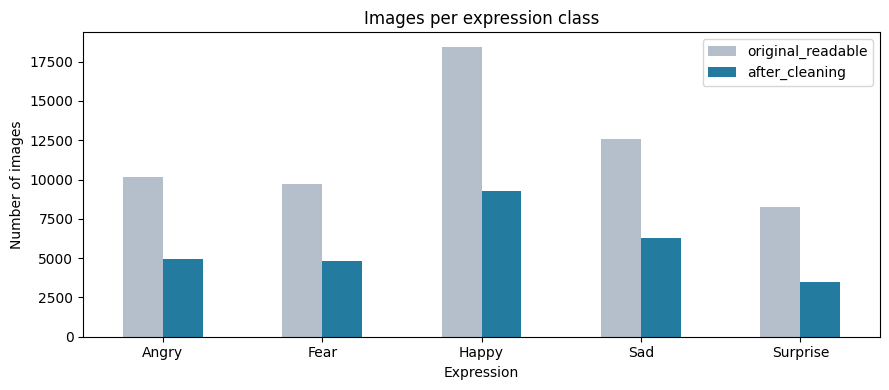

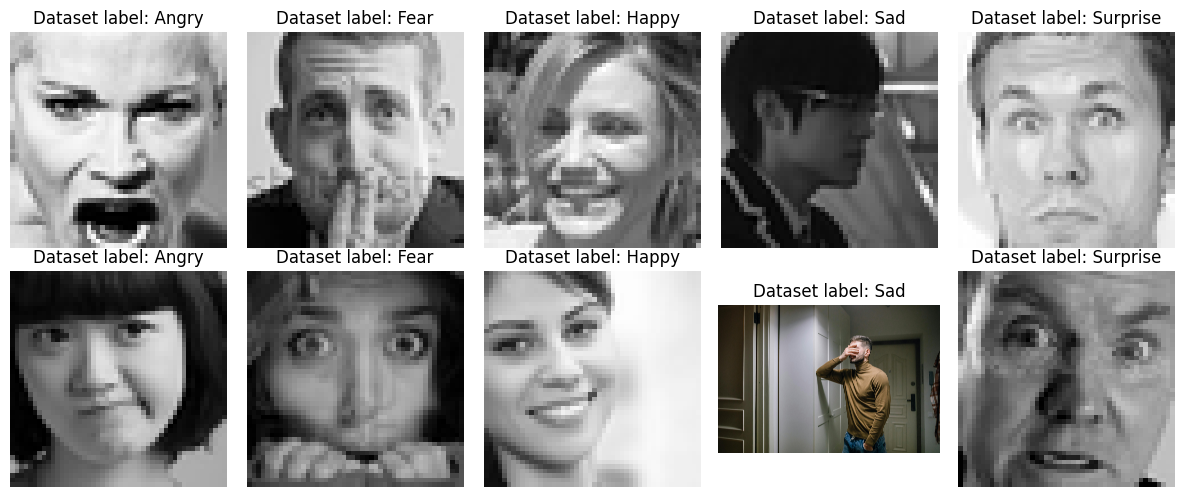

,image_size,width,height,image_count
0,48 x 48,48,48,57756
1,640 x 640,640,640,864
2,4000 x 6000,4000,6000,23
3,150 x 100,150,100,16
4,6000 x 4000,6000,4000,16
5,1600 x 1067,1600,1067,12
6,150 x 225,150,225,7
7,4480 x 6720,4480,6720,7
8,6720 x 4480,6720,4480,7
9,2000 x 3000,2000,3000,6


In [5]:
counts.plot(kind='bar', figsize=(9, 4), color=['#b5becb', '#247ba0'])
plt.title('Images per expression class')
plt.xlabel('Expression')
plt.ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
if RESUME_RUN_DIR is None:
    plt.savefig(RUN_DIR / 'class_distribution.png', dpi=150)
plt.show()

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(12, 5))
for column, label in enumerate(CLASS_NAMES):
    examples = clean[clean.label == label].sample(2, random_state=SEED)
    for row, (_, item) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / item.path) as image:
            axes[row, column].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, column].set_title(f'Dataset label: {label}')
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()
image_sizes = (
    manifest.groupby(['width', 'height'])
    .size()
    .reset_index(name='image_count')
    .sort_values('image_count', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

image_sizes.insert(0, 'image_size', image_sizes['width'].astype(str) + ' x ' + image_sizes['height'].astype(str))
display(image_sizes)


## 5. Split identik dan audit kebocoran data

Lakukan pembagian stratified sama seperti baseline. Hash mencakup nama file,
label, hash piksel hasil decode, serta keanggotaan split; seed saja tidak
dianggap cukup. Duplikat piksel persis dibuang sebelum split dan dicek
lagi setelah split. Jika jumlah atau hash berubah, training berhenti.

In [6]:
train_df, remaining_df = train_test_split(
    clean,
    test_size=0.30,
    stratify=clean.target,
    random_state=SEED
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df.target,
    random_state=SEED
)

train_df, val_df, test_df = (
    frame.reset_index(drop=True)
    for frame in (train_df, val_df, test_df)
)

split_manifest = pd.concat([
    train_df.assign(split='train'),
    val_df.assign(split='validation'),
    test_df.assign(split='test')
], ignore_index=True)

assert split_manifest.path.is_unique
assert split_manifest.pixel_sha256.is_unique
assert len(split_manifest) == len(clean)
assert set(train_df.target) == set(val_df.target) == set(test_df.target) == set(range(len(CLASS_NAMES)))


display(
    pd.crosstab(
        split_manifest.label,
        split_manifest.split
    ).reindex(CLASS_NAMES)[['train', 'validation', 'test']]
)

print('No exact decoded-pixel duplicates cross the splits.')

# Fingerprint exact membership and labels before resuming training.
split_rows = split_manifest[['split', 'path', 'target', 'pixel_sha256']].sort_values(['split', 'path'])
config['split_sha256'] = hashlib.sha256(split_rows.to_csv(index=False).encode('utf-8')).hexdigest()
assert len(clean) == 28818 and (len(train_df), len(val_df), len(test_df)) == EXPECTED_SPLIT_COUNTS
assert config['split_sha256'] == EXPECTED_SPLIT_SHA256, 'Split differs from SimpleCNN baseline.'
config_path = RUN_DIR / 'config.json'
if RESUME_RUN_DIR is None:
    config_path.write_text(json.dumps(config, indent=2))
    (RUN_DIR / 'environment_versions.json').write_text(json.dumps(versions, indent=2))
else:
    assert config_path.is_file(), 'Missing config.json in resume directory.'
    saved_config = json.loads(config_path.read_text())
    if saved_config != config:
        raise ValueError('Resume rejected: training configuration or split differs from this run.')
split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
print('Split SHA-256:', config['split_sha256'])

split,train,validation,test
label,,,
Angry,3471,744,744
Fear,3375,723,724
Happy,6478,1389,1388
Sad,4417,946,947
Surprise,2431,521,520


No exact decoded-pixel duplicates cross the splits.
Split SHA-256: 1ef54c784c90e488f83b1db34cf96358f0376a17f648cfdf6feb31e4125b0f1b


## 6. Transform RGB dan DataLoader

File dibuka dengan koreksi orientasi EXIF dan dikonversi ke RGB. Training
saja memakai horizontal flip, rotasi ±7° dan translasi ±4%. Validation
dan test hanya di-resize ke 160×160, diubah ke tensor, lalu dinormalisasi
dengan mean/std ImageNet. Tidak ada augmentation acak saat evaluasi.

In [7]:
base_train_steps = [
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=AUGMENT_DEGREES,
                            translate=(AUGMENT_TRANSLATE, AUGMENT_TRANSLATE),
                            interpolation=transforms.InterpolationMode.BILINEAR,
                            fill=(128, 128, 128)),
]
tensor_steps = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
train_transform = transforms.Compose(base_train_steps + tensor_steps)
if STAGE2_PHOTOMETRIC:
    photometric_step = transforms.RandomApply(
        [transforms.ColorJitter(brightness=BRIGHTNESS_JITTER, contrast=CONTRAST_JITTER)],
        p=PHOTOMETRIC_P)
    stage2_train_transform = transforms.Compose(base_train_steps + [photometric_step] + tensor_steps)
else:
    stage2_train_transform = train_transform
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FaceDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.frame = frame.reset_index(drop=True)
        self.root, self.transform = Path(root), transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        item = self.frame.iloc[index]
        with Image.open(self.root / item.path) as image:
            rgb = ImageOps.exif_transpose(image).convert('RGB')
            tensor = self.transform(rgb)
        return tensor, int(item.target)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)

def make_loaders():
    generator = torch.Generator().manual_seed(SEED)
    options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                   pin_memory=True, worker_init_fn=seed_worker)
    train = DataLoader(FaceDataset(train_df, DATA_DIR, train_transform),
                       shuffle=True, generator=generator, **options)
    validation = DataLoader(FaceDataset(val_df, DATA_DIR, eval_transform),
                            shuffle=False, **options)
    test = DataLoader(FaceDataset(test_df, DATA_DIR, eval_transform),
                      shuffle=False, **options)
    return train, validation, test

train_loader, val_loader, test_loader = make_loaders()
images, labels = next(iter(val_loader))
assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.shape == (BATCH_SIZE,)
print('Input batch:', tuple(images.shape), 'labels:', tuple(labels.shape))

Input batch: (64, 3, 160, 160) labels: (64,)


## 7. Pretrained ResNet18 dan classifier lima kelas

`ResNet18_Weights.DEFAULT` memuat bobot ImageNet. Fully connected head
diganti menjadi dropout 0,3 dan linear lima keluaran. Uji forward berikut
memakai tensor sintetis tanpa training untuk memastikan shape output.

In [8]:
pretrained_weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=pretrained_weights)
in_features = model.fc.in_features
assert in_features == 512, 'Unexpected ResNet18 classifier input width.'
model.fc = nn.Sequential(nn.Dropout(HEAD_DROPOUT), nn.Linear(in_features, len(CLASS_NAMES)))
model = model.to(DEVICE)
model.eval()
with torch.inference_mode():
    sample_logits = model(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
assert sample_logits.shape == (2, len(CLASS_NAMES))
assert model.fc[-1].out_features == 5
print('Pretrained weights:', pretrained_weights)
print('Classifier outputs:', model.fc[-1].out_features)
print('Model output shape:', tuple(sample_logits.shape))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]


Pretrained weights: ResNet18_Weights.IMAGENET1K_V1
Classifier outputs: 5
Model output shape: (2, 5)


## 8. Loss, freeze/unfreeze, BatchNorm, dan AMP

Bobot kelas dihitung hanya dari train. Stage 1 memakai weighted cross-entropy
yang sama dengan run sebelumnya. Stage 2 memakai target-weighted label
smoothing bila epsilon > 0; bobot ditentukan oleh label asli, lalu distribusi
target dicampur dengan uniform. Dengan epsilon 0, objective identik dengan
weighted cross-entropy lama. Untuk menjaga perbandingan loss lintas eksperimen,
kolom loss selalu weighted cross-entropy tanpa smoothing; kolom
objective_loss mencatat loss yang benar-benar dioptimalkan.

Stage 1 hanya melatih fc; backbone dalam mode eval. Stage 2 membuka
layer4 dan fc, dengan seluruh BatchNorm tetap eval. Photometric jitter
ringan diterapkan hanya pada training Stage 2 ketika varian mengaktifkannya.
Validation dan test tetap menggunakan transform deterministik. AMP float16
dan GradScaler aktif pada GPU T4.


In [9]:
train_counts = np.bincount(train_df.target.to_numpy(), minlength=len(CLASS_NAMES))
assert len(train_counts) == len(CLASS_NAMES) and (train_counts > 0).all()
class_weights = len(train_df) / (len(CLASS_NAMES) * train_counts)
class_weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
reference_criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)

class TargetWeightedLabelSmoothingLoss(nn.Module):
    def __init__(self, weights, epsilon):
        super().__init__()
        assert 0.0 <= epsilon < 1.0
        self.register_buffer('weight', weights.detach().clone())
        self.epsilon = float(epsilon)

    def forward(self, logits, targets):
        log_prob = torch.log_softmax(logits.float(), dim=1)
        hard_loss = -log_prob.gather(1, targets[:, None]).squeeze(1)
        uniform_loss = -log_prob.mean(dim=1)
        sample_weight = self.weight[targets]
        smoothed_loss = (1 - self.epsilon) * hard_loss + self.epsilon * uniform_loss
        return (sample_weight * smoothed_loss).sum() / sample_weight.sum()

stage_criteria = {'stage1': reference_criterion,
                  'stage2': (TargetWeightedLabelSmoothingLoss(
                      class_weight_tensor, STAGE2_LABEL_SMOOTHING)
                      if STAGE2_LABEL_SMOOTHING > 0 else reference_criterion)}
with torch.inference_mode():
    probe_logits = torch.tensor([[1.0, -0.5, 0.3, 0.2, -0.2],
                                 [-0.2, 0.4, 0.1, 1.5, 0.0]], device=DEVICE)
    probe_targets = torch.tensor([0, 3], device=DEVICE)
    assert torch.allclose(TargetWeightedLabelSmoothingLoss(class_weight_tensor, 0)(
        probe_logits, probe_targets), reference_criterion(probe_logits, probe_targets), atol=1e-6)
probe_with_grad = torch.tensor([[0.3, -0.1, 0.2, 0.8, -0.4]],
                               device=DEVICE, requires_grad=True)
probe_loss = TargetWeightedLabelSmoothingLoss(
    class_weight_tensor, STAGE2_LABEL_SMOOTHING)(
        probe_with_grad, torch.tensor([CLASS_TO_INDEX['Fear']], device=DEVICE))
probe_loss.backward()
assert torch.isfinite(probe_loss) and torch.isfinite(probe_with_grad.grad).all()
class_weight_table = pd.DataFrame({'class': CLASS_NAMES, 'train_count': train_counts,
                                   'loss_weight': class_weights})
class_weight_table.to_csv(RUN_DIR / 'class_weights.csv', index=False)
display(class_weight_table)

def configure_stage(stage):
    assert stage in ('stage1', 'stage2')
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    for parameter in model.fc.parameters():
        parameter.requires_grad_(True)
    if stage == 'stage2':
        for parameter in model.layer4.parameters():
            parameter.requires_grad_(True)
    assert all(parameter.requires_grad for parameter in model.fc.parameters())
    assert all(parameter.requires_grad == (stage == 'stage2')
               for parameter in model.layer4.parameters())
    assert all(not parameter.requires_grad for name, parameter in model.named_parameters()
               if not name.startswith(('fc.', 'layer4.')))

def set_model_mode(stage, training):
    if not training:
        model.eval()
    elif stage == 'stage1':
        model.eval()
        model.fc.train()
    else:
        model.train()
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()
    assert not any(module.training for module in model.modules()
                   if isinstance(module, nn.modules.batchnorm._BatchNorm))

configure_stage('stage1')
set_model_mode('stage1', True)
assert not any(p.requires_grad for p in model.layer4.parameters())
print('Stage 1 trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
configure_stage('stage2')
set_model_mode('stage2', True)
assert all(p.requires_grad for p in model.layer4.parameters())
print('Stage 2 trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
configure_stage('stage1')
model.eval()

def run_epoch(stage, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    set_model_mode(stage, training)
    criterion = stage_criteria[stage]
    loss_sum, objective_sum, loss_denominator = 0.0, 0.0, 0.0
    all_targets, all_predictions, all_probabilities = [], [], []
    for batch_images, targets in tqdm(loader, desc='Train' if training else 'Evaluate', leave=False):
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(batch_images)
                objective_loss = criterion(logits, targets)
                if criterion is reference_criterion:
                    reference_loss = objective_loss.detach()
                else:
                    with torch.no_grad():
                        reference_loss = reference_criterion(logits.detach(), targets)
            if training:
                scaler.scale(objective_loss).backward()
                scaler.step(optimizer)
                scaler.update()
        denominator = reference_criterion.weight[targets].sum().item()
        loss_sum += reference_loss.item() * denominator
        objective_sum += objective_loss.item() * denominator
        loss_denominator += denominator
        all_targets.extend(targets.detach().cpu().tolist())
        all_predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
        if not training:
            all_probabilities.append(torch.softmax(logits.detach().float(), dim=1).cpu().numpy())
    metrics = {'loss': float(loss_sum / loss_denominator),
               'objective_loss': float(objective_sum / loss_denominator),
               'accuracy': float(accuracy_score(all_targets, all_predictions)),
               'macro_f1': float(f1_score(all_targets, all_predictions,
                                          labels=list(range(len(CLASS_NAMES))),
                                          average='macro', zero_division=0))}
    probabilities = np.concatenate(all_probabilities) if all_probabilities else None
    return metrics, np.asarray(all_targets), np.asarray(all_predictions), probabilities

,class,train_count,loss_weight
0,Angry,3471,1.162316
1,Fear,3375,1.195378
2,Happy,6478,0.622785
3,Sad,4417,0.913380
4,Surprise,2431,1.659564


Stage 1 trainable parameters: 2565
Stage 2 trainable parameters: 8396293


## 9. Dua tahap training dengan checkpoint dan resume terpisah

Tiap tahap mempunyai `best.pt`, `last.pt`, dan `history.csv` tersendiri.
Checkpoint memuat stage, konfigurasi, split, state optimizer/scheduler/AMP,
dan state RNG. Stage 2 selalu dimulai dari checkpoint terbaik stage 1,
kecuali ketika melanjutkan checkpoint stage 2 yang tervalidasi. Scheduler
dan early stopping memantau validation macro F1. Setelah kedua tahap,
checkpoint terbaik secara global dipilih dari **best stage 1** dan
**best stage 2**, sehingga fine-tuning yang memburuk tidak dipaksakan.

In [10]:
def stage_paths(stage):
    folder = RUN_DIR / stage
    folder.mkdir(exist_ok=True)
    return folder, folder / 'best.pt', folder / 'last.pt'

def verify_checkpoint(checkpoint, stage):
    if checkpoint.get('stage') != stage or checkpoint.get('config') != config:
        raise ValueError(f'Checkpoint {stage} ditolak: stage, config, atau split berbeda.')

def restore_rng(checkpoint):
    random.setstate(checkpoint['python_rng_state'])
    np_state = checkpoint['numpy_rng_state']
    np.random.set_state((np_state[0], np.array(np_state[1], dtype=np.uint32),
                         np_state[2], np_state[3], np_state[4]))
    torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
    torch.cuda.set_rng_state_all([state.cpu() for state in checkpoint['cuda_rng_state']])
    train_loader.generator.set_state(checkpoint['loader_rng_state'].cpu())

def run_stage(stage, initial_best_path=None):
    folder, best_path, last_path = stage_paths(stage)
    if stage == 'stage1' and not last_path.exists() and (RUN_DIR / 'stage2' / 'last.pt').exists():
        raise ValueError('Cannot resume stage2 without a traceable stage1 checkpoint.')
    train_loader.dataset.transform = train_transform if stage == 'stage1' else stage2_train_transform
    assert val_loader.dataset.transform is eval_transform
    configure_stage(stage)
    print(f'{stage} train transform: {train_loader.dataset.transform}')
    print(f'{stage} label smoothing: {0.0 if stage == "stage1" else STAGE2_LABEL_SMOOTHING:.2f}')
    if stage == 'stage1':
        groups = [{'params': model.fc.parameters(), 'lr': STAGE1_HEAD_LR}]
        max_epochs, patience = STAGE1_MAX_EPOCHS, STAGE1_PATIENCE
    else:
        groups = [{'params': model.layer4.parameters(), 'lr': STAGE2_LAYER4_LR},
                  {'params': model.fc.parameters(), 'lr': STAGE2_HEAD_LR}]
        max_epochs, patience = STAGE2_MAX_EPOCHS, STAGE2_PATIENCE
    stage_weight_decay = WEIGHT_DECAY if stage == 'stage1' else STAGE2_WEIGHT_DECAY
    optimizer = torch.optim.AdamW(groups, weight_decay=stage_weight_decay)
    assert all(group['weight_decay'] == stage_weight_decay for group in optimizer.param_groups)
    print(f'{stage} AdamW weight decay: {stage_weight_decay:.0e}')
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=SCHEDULER_FACTOR,
        patience=SCHEDULER_PATIENCE, threshold=MIN_DELTA,
        threshold_mode='abs', min_lr=MIN_LR)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    start_epoch, best_f1, best_epoch, stale, history = 1, -1.0, 0, 0, []

    if RESUME_RUN_DIR is not None and last_path.exists():
        checkpoint = torch.load(last_path, map_location=DEVICE, weights_only=True)
        verify_checkpoint(checkpoint, stage)
        assert best_path.is_file(), f'Missing best checkpoint for {stage}'
        best_saved = torch.load(best_path, map_location='cpu', weights_only=True)
        verify_checkpoint(best_saved, stage)
        if (best_saved['best_epoch'] != checkpoint['best_epoch'] or
                abs(best_saved['validation_macro_f1'] - checkpoint['best_f1']) > 1e-12):
            raise ValueError(f'Best/last checkpoint mismatch for {stage}.')
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_f1, best_epoch, stale = checkpoint['best_f1'], checkpoint['best_epoch'], checkpoint['stale']
        history = checkpoint['history']
        restore_rng(checkpoint)
        print(f'Resuming {stage} at epoch {start_epoch}')
    else:
        assert not best_path.exists() and not last_path.exists(), f'Partial checkpoint for {stage}'
        if stage == 'stage2':
            assert initial_best_path is not None and initial_best_path.is_file()
            initial = torch.load(initial_best_path, map_location=DEVICE, weights_only=True)
            verify_checkpoint(initial, 'stage1')
            model.load_state_dict(initial['model_state_dict'])
        print(f'Starting {stage} at epoch 1')

    for epoch in range(start_epoch, max_epochs + 1):
        if stale >= patience:
            break
        started = time.perf_counter()
        learning_rates = [group['lr'] for group in optimizer.param_groups]
        train_metrics, _, _, _ = run_epoch(stage, train_loader, optimizer, scaler)
        val_metrics, _, _, _ = run_epoch(stage, val_loader)
        scheduler.step(val_metrics['macro_f1'])
        history.append({'stage': stage, 'epoch': epoch,
                        'learning_rates': json.dumps(learning_rates),
                        **{f'train_{key}': value for key, value in train_metrics.items()},
                        **{f'val_{key}': value for key, value in val_metrics.items()},
                        'seconds': time.perf_counter() - started})
        print(f"{stage} {epoch}/{max_epochs}: train loss {train_metrics['loss']:.4f}, "
              f"val loss {val_metrics['loss']:.4f}, val accuracy {val_metrics['accuracy']:.4f}, "
              f"val macro F1 {val_metrics['macro_f1']:.4f}")
        if val_metrics['macro_f1'] > best_f1 + MIN_DELTA:
            best_f1, best_epoch, stale = val_metrics['macro_f1'], epoch, 0
            best_payload = {'stage': stage, 'config': config,
                            'model_state_dict': {name: value.detach().cpu()
                                                 for name, value in model.state_dict().items()},
                            'best_epoch': best_epoch, 'validation_macro_f1': float(best_f1)}
            temp = folder / 'best.tmp'
            torch.save(best_payload, temp)
            os.replace(temp, best_path)
        else:
            stale += 1

        np_state = np.random.get_state()
        last_payload = {'stage': stage, 'config': config, 'epoch': epoch,
                        'model_state_dict': model.state_dict(),
                        'optimizer_state_dict': optimizer.state_dict(),
                        'scheduler_state_dict': scheduler.state_dict(),
                        'scaler_state_dict': scaler.state_dict(),
                        'best_f1': float(best_f1), 'best_epoch': best_epoch,
                        'stale': stale, 'history': history,
                        'python_rng_state': random.getstate(),
                        'numpy_rng_state': (np_state[0], np_state[1].tolist(),
                                            int(np_state[2]), int(np_state[3]), float(np_state[4])),
                        'torch_rng_state': torch.get_rng_state(),
                        'cuda_rng_state': torch.cuda.get_rng_state_all(),
                        'loader_rng_state': train_loader.generator.get_state()}
        temp = folder / 'last.tmp'
        torch.save(last_payload, temp)
        os.replace(temp, last_path)
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        if stale >= patience:
            print(f'{stage} early stopping at epoch {epoch}')
            break
    assert best_path.is_file(), f'No best checkpoint for {stage}'
    best = torch.load(best_path, map_location='cpu', weights_only=True)
    verify_checkpoint(best, stage)
    (folder / 'summary.json').write_text(json.dumps(
        {'stage': stage, 'best_epoch': best['best_epoch'],
         'validation_macro_f1': best['validation_macro_f1'],
         'epochs_completed': len(history)}, indent=2))
    print(f"{stage} best epoch {best['best_epoch']}, validation macro F1 {best['validation_macro_f1']:.4f}")
    return best_path, best

stage1_path, stage1_best = run_stage('stage1')
stage2_path, stage2_best = run_stage('stage2', initial_best_path=stage1_path)
winner = stage2_best if stage2_best['validation_macro_f1'] > stage1_best['validation_macro_f1'] else stage1_best
WINNING_STAGE = winner['stage']
global_best_path = RUN_DIR / 'best_model.pt'
torch.save(winner, RUN_DIR / 'best_model.tmp')
os.replace(RUN_DIR / 'best_model.tmp', global_best_path)
print('Global best:', WINNING_STAGE, 'epoch', winner['best_epoch'],
      'validation macro F1', winner['validation_macro_f1'])

stage1 train transform: Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-7.0, 7.0], translate=(0.04, 0.04), interpolation=bilinear, fill=(128, 128, 128))
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
stage1 label smoothing: 0.00
stage1 AdamW weight decay: 1e-04
Starting stage1 at epoch 1


Train:   0%|          | 0/316 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

stage1 1/8: train loss 1.4403, val loss 1.3169, val accuracy 0.4879, val macro F1 0.4366


Train:   0%|          | 0/316 [00:00<?, ?it/s]

...

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

stage2 22/25: train loss 0.1569, val loss 0.9938, val accuracy 0.7129, val macro F1 0.6817


Train:   0%|          | 0/316 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

stage2 23/25: train loss 0.1509, val loss 0.9731, val accuracy 0.7023, val macro F1 0.6769
stage2 early stopping at epoch 23
stage2 best epoch 17, validation macro F1 0.6841
Global best: stage2 epoch 17 validation macro F1 0.6841065221879029


## 10. Evaluasi checkpoint terbaik pada validation

Semua metrik di bawah memakai checkpoint yang dipilih berdasarkan
validation macro F1. `val_loader` tidak diacak dan tidak memakai
augmentation. Test set tidak dipakai untuk memilih stage atau hyperparameter.

In [11]:
best_checkpoint = torch.load(global_best_path, map_location=DEVICE, weights_only=True)
verify_checkpoint(best_checkpoint, WINNING_STAGE)
configure_stage(WINNING_STAGE)
model.load_state_dict(best_checkpoint['model_state_dict'])
val_metrics_best, val_true, val_pred, val_probs = run_epoch(WINNING_STAGE, val_loader)
assert len(val_true) == len(val_df) == 4323
assert np.array_equal(val_true, val_df.target.to_numpy())
validation_results = {**val_metrics_best, 'winning_stage': WINNING_STAGE,
                      'best_epoch': best_checkpoint['best_epoch'],
                      'validation_samples': len(val_df)}
(RUN_DIR / 'validation_metrics.json').write_text(json.dumps(validation_results, indent=2))
print(json.dumps(validation_results, indent=2))

# Diagnostic only: no model selection or hyperparameter tuning uses this result.
train_eval_loader = DataLoader(
    FaceDataset(train_df, DATA_DIR, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
train_eval_metrics, train_eval_true, _, _ = run_epoch(WINNING_STAGE, train_eval_loader)
assert len(train_eval_true) == len(train_df)
assert np.array_equal(train_eval_true, train_df.target.to_numpy())
(RUN_DIR / 'best_checkpoint_train_eval_metrics.json').write_text(
    json.dumps(train_eval_metrics, indent=2))
generalization_gap = {
    'checkpoint_stage': WINNING_STAGE,
    'checkpoint_epoch': best_checkpoint['best_epoch'],
    'train_eval_accuracy': train_eval_metrics['accuracy'],
    'validation_accuracy': val_metrics_best['accuracy'],
    'accuracy_gap_percentage_points':
        100 * (train_eval_metrics['accuracy'] - val_metrics_best['accuracy']),
    'train_eval_macro_f1': train_eval_metrics['macro_f1'],
    'validation_macro_f1': val_metrics_best['macro_f1'],
    'macro_f1_gap_percentage_points':
        100 * (train_eval_metrics['macro_f1'] - val_metrics_best['macro_f1']),
    'train_eval_reference_loss': train_eval_metrics['loss'],
    'validation_reference_loss': val_metrics_best['loss'],
    'reference_loss_gap': val_metrics_best['loss'] - train_eval_metrics['loss'],
}
(RUN_DIR / 'best_checkpoint_generalization_gap.json').write_text(
    json.dumps(generalization_gap, indent=2))
print('Matched-protocol best-checkpoint gap:')
print(json.dumps(generalization_gap, indent=2))


Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

{
  "loss": 0.9418516632581381,
  "objective_loss": 1.069362146831735,
  "accuracy": 0.7069164931760351,
  "macro_f1": 0.6841065221879029,
  "winning_stage": "stage2",
  "best_epoch": 17,
  "validation_samples": 4323
}


Evaluate:   0%|          | 0/316 [00:00<?, ?it/s]

Matched-protocol best-checkpoint gap:
{
  "checkpoint_stage": "stage2",
  "checkpoint_epoch": 17,
  "train_eval_accuracy": 0.946559587547095,
  "validation_accuracy": 0.7069164931760351,
  "accuracy_gap_percentage_points": 23.96430943710599,
  "train_eval_macro_f1": 0.942398509205389,
  "validation_macro_f1": 0.6841065221879029,
  "macro_f1_gap_percentage_points": 25.829198701748613,
  "train_eval_reference_loss": 0.19569192786808318,
  "validation_reference_loss": 0.9418516632581381,
  "reference_loss_gap": 0.7461597353900549
}


## 11. Riwayat training dan grafik

Sumbu epoch global menempatkan stage 2 setelah stage 1; garis vertikal
menunjukkan transisi. Loss berbobot dalam eksperimen ini dihitung dengan
bobot kelas train yang sama pada kedua stage.

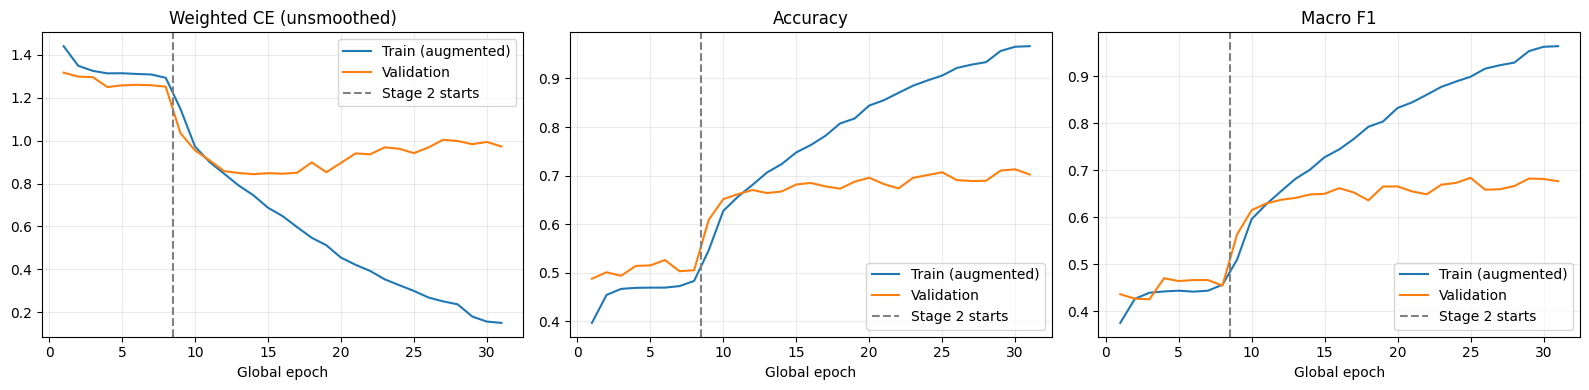

,stage,epoch,learning_rates,train_loss,train_objective_loss,train_accuracy,train_macro_f1,val_loss,val_objective_loss,val_accuracy,val_macro_f1,seconds,global_epoch
0,stage1,1,[0.001],1.440267,1.440267,0.396936,0.375712,1.316929,1.316929,0.487856,0.436648,168.617084,1
1,stage1,2,[0.001],1.348857,1.348857,0.454491,0.426843,1.298395,1.298395,0.501041,0.427123,162.245236,2
2,stage1,3,[0.001],1.325126,1.325126,0.466885,0.439855,1.295895,1.295895,0.493870,0.425914,163.932952,3
3,stage1,4,[0.001],1.313543,1.313543,0.469016,0.442530,1.249775,1.249775,0.514226,0.470676,163.943734,4
4,stage1,5,[0.001],1.314033,1.314033,0.469512,0.444178,1.257757,1.257757,0.515152,0.464716,163.303393,5
5,stage1,6,[0.001],1.310819,1.310819,0.469512,0.442106,1.260180,1.260180,0.526255,0.466725,162.836618,6
6,stage1,7,[0.001],1.308271,1.308271,0.472635,0.444111,1.258285,1.258285,0.503354,0.466855,162.251177,7
7,stage1,8,[0.0005],1.292848,1.292848,0.483244,0.456837,1.251303,1.251303,0.505205,0.455024,161.621763,8
8,stage2,1,"[0.0001, 0.0005]",1.148948,1.203489,0.546252,0.510111,1.035612,1.105550,0.608836,0.563638,173.115650,9
9,stage2,2,"[0.0001, 0.0005]",0.973086,1.050066,0.627404,0.596389,0.954823,1.041746,0.651631,0.615282,174.914404,10


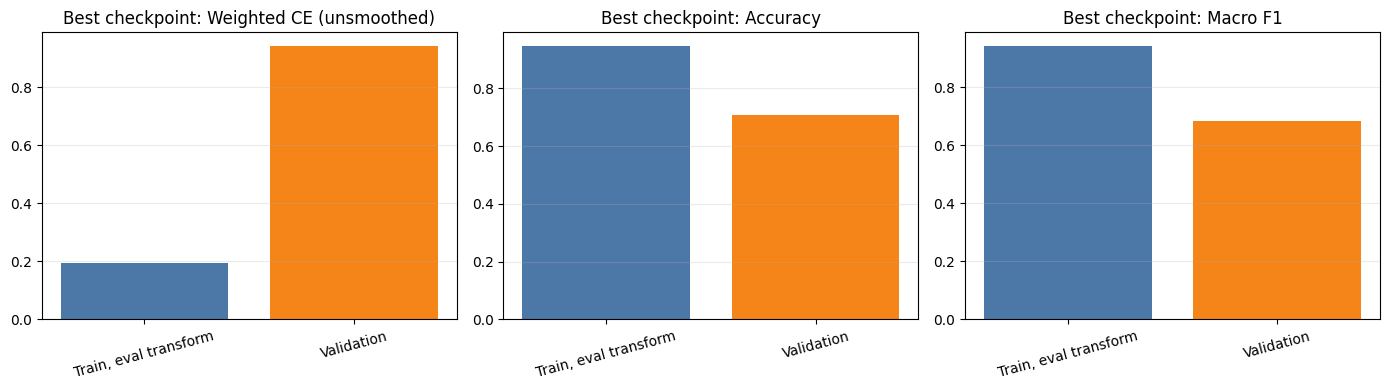

In [12]:
history_parts = []
for stage in ('stage1', 'stage2'):
    part = pd.read_csv(RUN_DIR / stage / 'history.csv')
    history_parts.append(part)
history_df = pd.concat(history_parts, ignore_index=True)
history_df['global_epoch'] = np.arange(1, len(history_df) + 1)
history_df.to_csv(RUN_DIR / 'training_history.csv', index=False)
stage_boundary = len(history_parts[0]) + 0.5
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, metric in zip(axes, ('loss', 'accuracy', 'macro_f1')):
    axis.plot(history_df.global_epoch, history_df[f'train_{metric}'], label='Train (augmented)')
    axis.plot(history_df.global_epoch, history_df[f'val_{metric}'], label='Validation')
    axis.axvline(stage_boundary, color='gray', linestyle='--', label='Stage 2 starts')
    axis.set(title=('Weighted CE (unsmoothed)' if metric == 'loss'
                    else metric.replace('_', ' ').title()), xlabel='Global epoch')
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / 'training_curves.png', dpi=150)
plt.show()
display(history_df)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, metric, title in zip(
    axes, ('loss', 'accuracy', 'macro_f1'),
    ('Weighted CE (unsmoothed)', 'Accuracy', 'Macro F1')):
    values = [train_eval_metrics[metric], val_metrics_best[metric]]
    axis.bar(['Train, eval transform', 'Validation'], values,
             color=['#4C78A8', '#F58518'])
    axis.set_title(f'Best checkpoint: {title}')
    axis.grid(axis='y', alpha=0.25)
    axis.tick_params(axis='x', labelrotation=15)
plt.tight_layout()
plt.savefig(RUN_DIR / 'best_checkpoint_generalization_gap.png', dpi=150)
plt.show()


## 12. Classification report, confusion matrix, dan kesalahan utama

Simpan seluruh prediksi validation agar Fear, Angry, dan Sad dapat
dianalisis kembali. Tabel fokus menunjukkan kelas tujuan salah prediksi,
jumlah kesalahan, dan proporsinya di antara sampel kelas asal. Contoh
salah prediksi berconfidence tinggi membantu meninjau ambiguitas atau label.
Grafik train per epoch memakai augmentasi dan mode training; grafik gap
checkpoint terbaik membandingkan train dan validation dengan transform
evaluasi serta mode eval yang sama.


,precision,recall,f1-score,support
Angry,0.566185,0.684140,0.619598,744.000000
Fear,0.567568,0.493776,0.528107,723.000000
Happy,0.875000,0.881929,0.878451,1389.000000
Sad,0.637188,0.594080,0.614880,946.000000
Surprise,0.785575,0.773512,0.779497,521.000000
accuracy,0.706916,0.706916,0.706916,0.706916
macro avg,0.686303,0.685488,0.684107,4323.000000
weighted avg,0.707618,0.706916,0.705705,4323.000000


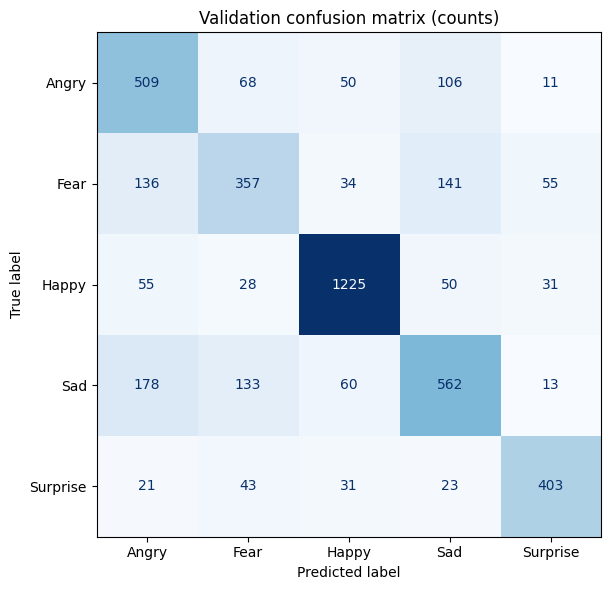

,label,predicted_label,errors,class_support,fraction_of_true_class
2,Angry,Sad,106,744,0.142473
0,Angry,Fear,68,744,0.091398
1,Angry,Happy,50,744,0.067204
3,Angry,Surprise,11,744,0.014785
6,Fear,Sad,141,723,0.195021
4,Fear,Angry,136,723,0.188105
7,Fear,Surprise,55,723,0.076072
5,Fear,Happy,34,723,0.047026
8,Sad,Angry,178,946,0.188161
9,Sad,Fear,133,946,0.140592


,path,label,target,predicted_index,predicted_label,predicted_confidence,true_class_probability
1797,Sad/28168.png,Sad,3,1,Fear,0.997105,0.002106
3690,Fear/29726.png,Fear,1,0,Angry,0.996348,0.000443
335,Sad/114328711.png,Sad,3,0,Angry,0.995906,0.000748
814,Sad/524832151.png,Sad,3,1,Fear,0.994961,0.002618
526,Fear/670194196.png,Fear,1,3,Sad,0.994040,0.002347
2525,Sad/162627980.png,Sad,3,1,Fear,0.993772,0.005511
551,Sad/125800277.png,Sad,3,1,Fear,0.993561,0.002470
4018,Fear/350698485.png,Fear,1,4,Surprise,0.993183,0.002781
1702,Sad/383304481.png,Sad,3,0,Angry,0.992878,0.002628
3851,Fear/582626113.png,Fear,1,0,Angry,0.992722,0.002383


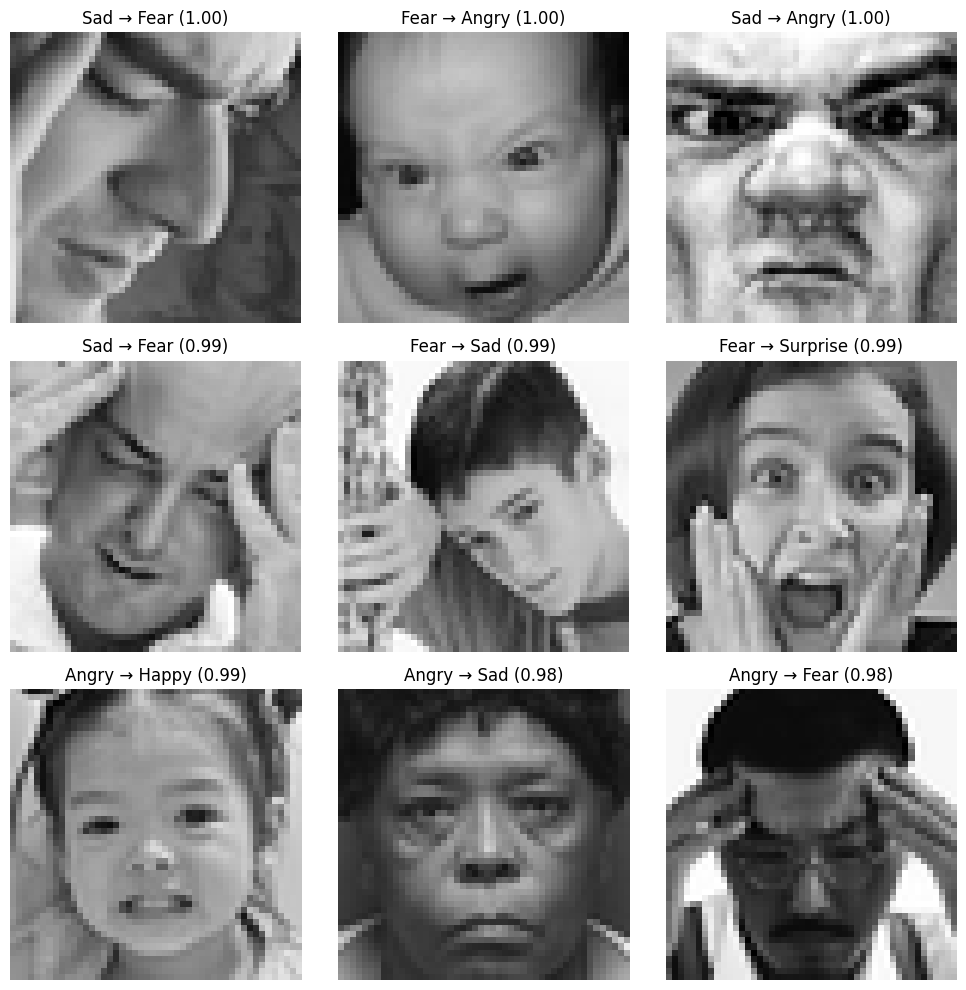

In [13]:
class_ids = list(range(len(CLASS_NAMES)))
report = classification_report(val_true, val_pred, labels=class_ids,
                               target_names=CLASS_NAMES, output_dict=True,
                               zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(RUN_DIR / 'validation_classification_report.csv')
report_df.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']].to_csv(
    RUN_DIR / 'validation_per_class_metrics.csv')
display(report_df)

predictions = val_df[['path', 'label', 'target']].copy()
predictions['predicted_index'] = val_pred
predictions['predicted_label'] = [CLASS_NAMES[index] for index in val_pred]
predictions['predicted_confidence'] = val_probs.max(axis=1)
predictions['true_class_probability'] = val_probs[np.arange(len(val_true)), val_true]
predictions.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)

cm = confusion_matrix(val_true, val_pred, labels=class_ids)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    RUN_DIR / 'validation_confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Validation confusion matrix (counts)')
plt.tight_layout()
plt.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=150)
plt.show()

focus_classes = ['Fear', 'Angry', 'Sad']
focus_errors = predictions[predictions.label.isin(focus_classes) &
                           (predictions.label != predictions.predicted_label)].copy()
focus_errors.to_csv(RUN_DIR / 'validation_focus_errors.csv', index=False)
focus_summary = (focus_errors.groupby(['label', 'predicted_label']).size()
                 .rename('errors').reset_index())
focus_summary['class_support'] = focus_summary.label.map(
    {name: int(report[name]['support']) for name in focus_classes})
focus_summary['fraction_of_true_class'] = focus_summary.errors / focus_summary.class_support
focus_summary.sort_values(['label', 'errors'], ascending=[True, False], inplace=True)
focus_summary.to_csv(RUN_DIR / 'validation_focus_errors_summary.csv', index=False)
display(focus_summary)
display(focus_errors.sort_values('predicted_confidence', ascending=False).head(12))

examples = (focus_errors.sort_values('predicted_confidence', ascending=False)
            .groupby('label', group_keys=False).head(3))
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for axis in axes.flat:
    axis.axis('off')
for axis, (_, item) in zip(axes.flat, examples.iterrows()):
    with Image.open(DATA_DIR / item.path) as image:
        axis.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    axis.set_title(f"{item.label} → {item.predicted_label} ({item.predicted_confidence:.2f})")
    axis.axis('off')
plt.tight_layout()
plt.savefig(RUN_DIR / 'validation_focus_error_examples.png', dpi=150)
plt.show()

## 13. Perbandingan dengan baseline tersimpan

Pembanding utama adalah run ResNet18 Stage 2 weight decay 1e-3 terakhir
yang outputnya sudah tersimpan (best epoch 15, validation macro F1 67,23%).
Run lama berhenti pada batas 15 epoch; batas baru 25 epoch, dengan early
stopping tetap aktif. Jalankan varian baseline untuk mengisolasi efek
budget epoch sebelum menyimpulkan kontribusi regularisasi.
Angka pada baris baru dihitung hanya setelah run Colab ini selesai.
Semua baris menggunakan validation split yang sama (4.323 gambar).
Perbandingan dengan SimpleCNN dipengaruhi arsitektur dan protokol input
yang berbeda. Varian baseline, smoothing_only, photometric_only,
dan combined dapat dipilih satu per run untuk ablation. Tidak ada
evaluasi test untuk memilih konfigurasi.


In [14]:
assert config['split_sha256'] == EXPECTED_SPLIT_SHA256
comparison = pd.DataFrame([
    {'experiment': 'SimpleCNN 50 epoch', 'validation_accuracy': 0.6232,
     'validation_macro_f1': 0.5956, 'source': 'CNN.ipynb best-F1 validation'},
    {'experiment': 'CNN Improved', 'validation_accuracy': 0.6414526948878094,
     'validation_macro_f1': 0.6139146030830311, 'source': 'CNN_improved.ipynb output'},
    {'experiment': 'CNN Fear Weight 1.25x', 'validation_accuracy': 0.6393708073097386,
     'validation_macro_f1': 0.6174599263337421, 'source': 'CNN_fear_weight.ipynb output'},
    {'experiment': 'ResNet18 Stage 2 WD 1e-4', 'validation_accuracy': 0.6983576220217441,
     'validation_macro_f1': 0.6686474465717642,
     'source': 'previous Stage 2 epoch 11 best-F1 checkpoint'},
    {'experiment': 'ResNet18 Stage 2 WD 1e-3', 'validation_accuracy': 0.6972010178117048,
     'validation_macro_f1': 0.6722967190525322,
     'source': 'saved Stage 2 epoch 15 best-F1 checkpoint'},
    {'experiment': f'ResNet18 {EXPERIMENT_VARIANT}',
     'validation_accuracy': val_metrics_best['accuracy'],
     'validation_macro_f1': val_metrics_best['macro_f1'],
     'source': f'this run, {WINNING_STAGE} best-F1 checkpoint'},
])
comparison['accuracy_percent'] = comparison.validation_accuracy * 100
comparison['macro_f1_percent'] = comparison.validation_macro_f1 * 100
comparison.to_csv(RUN_DIR / 'validation_comparison.csv', index=False)
display(comparison)
baseline_fear = {'precision': 399 / 783, 'recall': 399 / 723,
                 'f1': 798 / (783 + 723)}
fear_delta = {metric: (report['Fear'][report_key] - baseline_fear[metric]) * 100
              for metric, report_key in [('precision', 'precision'), ('recall', 'recall'),
                                         ('f1', 'f1-score')]}
comparison_summary = {
    'baseline_validation_macro_f1': 0.6722967190525322,
    'new_validation_macro_f1': val_metrics_best['macro_f1'],
    'macro_f1_delta_percentage_points':
        (val_metrics_best['macro_f1'] - 0.6722967190525322) * 100,
    'baseline_validation_accuracy': 0.6972010178117048,
    'new_validation_accuracy': val_metrics_best['accuracy'],
    'baseline_fear': baseline_fear,
    'new_fear': {key: report['Fear'][key] for key in ('precision', 'recall', 'f1-score')},
    'fear_delta_percentage_points': fear_delta,
}
(RUN_DIR / 'validation_vs_resnet_baseline.json').write_text(
    json.dumps(comparison_summary, indent=2))
print(json.dumps(comparison_summary, indent=2))


,experiment,validation_accuracy,validation_macro_f1,source,accuracy_percent,macro_f1_percent
0,SimpleCNN 50 epoch,0.623200,0.595600,CNN.ipynb best-F1 validation,62.320000,59.560000
1,CNN Improved,0.641453,0.613915,CNN_improved.ipynb output,64.145269,61.391460
2,CNN Fear Weight 1.25x,0.639371,0.617460,CNN_fear_weight.ipynb output,63.937081,61.745993
3,ResNet18 Stage 2 WD 1e-4,0.698358,0.668647,previous Stage 2 epoch 11 best-F1 checkpoint,69.835762,66.864745
4,ResNet18 Stage 2 WD 1e-3,0.697201,0.672297,saved Stage 2 epoch 15 best-F1 checkpoint,69.720102,67.229672
5,ResNet18 combined,0.706916,0.684107,"this run, stage2 best-F1 checkpoint",70.691649,68.410652


{
  "baseline_validation_macro_f1": 0.6722967190525322,
  "new_validation_macro_f1": 0.6841065221879029,
  "macro_f1_delta_percentage_points": 1.1809803135370722,
  "baseline_validation_accuracy": 0.6972010178117048,
  "new_validation_accuracy": 0.7069164931760351,
  "baseline_fear": {
    "precision": 0.5095785440613027,
    "recall": 0.5518672199170125,
    "f1": 0.5298804780876494
  },
  "new_fear": {
    "precision": 0.5675675675675675,
    "recall": 0.49377593360995853,
    "f1-score": 0.5281065088757396
  },
  "fear_delta_percentage_points": {
    "precision": 5.79890235062649,
    "recall": -5.809128630705396,
    "f1": -0.1773969211909754
  }
}


## 14. Evaluasi final test (dinonaktifkan)

Aktifkan hanya setelah keputusan model dan hyperparameter selesai
berdasarkan validation. Jangan memakai hasil test untuk tuning.

In [16]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    final_checkpoint = torch.load(global_best_path, map_location=DEVICE, weights_only=True)
    verify_checkpoint(final_checkpoint, WINNING_STAGE)
    configure_stage(WINNING_STAGE)
    model.load_state_dict(final_checkpoint['model_state_dict'])
    test_metrics, test_true, test_pred, _ = run_epoch(WINNING_STAGE, test_loader)
    test_report = classification_report(test_true, test_pred, labels=list(range(len(CLASS_NAMES))),
                                        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    (RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
    pd.DataFrame(test_report).transpose().to_csv(RUN_DIR / 'test_classification_report.csv')
    test_cm = confusion_matrix(test_true, test_pred, labels=list(range(len(CLASS_NAMES))))
    pd.DataFrame(test_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        RUN_DIR / 'test_confusion_matrix.csv')
    print(json.dumps(test_metrics, indent=2))
else:
    print('Final test evaluation is disabled. Select using validation only.')

Final test evaluation is disabled. Select using validation only.


## 15. Ekspor hasil

Semua checkpoint, grafik, CSV, dan metadata tetap tersimpan di Google Drive.
Sel ini juga membuat ZIP untuk diunduh; ukuran ZIP dapat besar karena
checkpoint tiap stage memuat state optimizer.

In [17]:
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS:
    from google.colab import files
    results_zip = shutil.make_archive(f'/content/{RUN_DIR.name}_resnet18_results',
                                      'zip', root_dir=RUN_DIR)
    files.download(results_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>